# Plots for Abby
- maps of mean, std, percent range in ET across obs products
- LAI-aridity bin percent range in ET across obs products

In [1]:
from pathlib import Path
from datetime import datetime

import numpy as np
import xarray as xr
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
from matplotlib.collections import LineCollection
import cartopy.crs as ccrs

import etunc.config as cfg
from etunc.plotting import set_edge_ticks, MAP_KWARGS

/glade/u/home/bbuchovecky/projects/et_unc/.pixi/envs/default/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
TO_SAVE = True

def finish(fig, fout, to_save=TO_SAVE):
    tnow = datetime.now().strftime("%Y-%m-%d %H:%M:%S")
    fig.suptitle(f"for-abby.ipynb - {tnow}\n{fout.name}", x=0.5, ha="center", fontsize=8)
    if to_save:
        if isinstance(fout, Path) and not fout.parent.exists():
            print(f"making dir: {fout.parent}")
            fout.parent.mkdir(parents=True, exist_ok=True)
        plt.savefig(fout, dpi=300, bbox_inches="tight")
        print(f"saved: {fout}")
    else:
        print(f"not saved: {fout}")

## Load results

In [3]:
PROC_ROOT = cfg.PROC_ROOT
PERIOD = "200101-201412"
BINS = "lai15_ai15"
TAG = f"qbin_pooled_all.{BINS}.1deg.{PERIOD}"
FAMILIES = ("obs", "era5", "cmip", "fppe", "ippe", "lens", "trendy_s3")
ET_BIN_VARIABLE = "et_clim"
BIN_VARIABLES = (ET_BIN_VARIABLE, "land_area")

FIG_ROOT = cfg.PROJ_ROOT / "for" / "aswann"

ORD_MEMBER = [
    'CLASS-GIMMS_LAI4g-GPCPv2.3-CERESed4.2',
    'DOLCE-GIMMS_LAI4g-GPCPv2.3-CERESed4.2',
    'FLUXCOM-GIMMS_LAI4g-GPCPv2.3-CERESed4.2',
    'MOD16A2-GIMMS_LAI4g-GPCPv2.3-CERESed4.2',
    'MODIS-GIMMS_LAI4g-GPCPv2.3-CERESed4.2',
    'PMLv2.2a_MODIS-GIMMS_LAI4g-GPCPv2.3-CERESed4.2',
    'PMLv2.2c-GIMMS_LAI4g-GPCPv2.3-CERESed4.2',
    'SiTHv2-GIMMS_LAI4g-GPCPv2.3-CERESed4.2',
    'GLEAMv3.3a-GIMMS_LAI4g-GPCPv2.3-CERESed4.2',
    'GLEAMv4.3a-GIMMS_LAI4g-GPCPv2.3-CERESed4.2',
    'GLEAMv4.3b-GIMMS_LAI4g-GPCPv2.3-CERESed4.2',
]

RNG_CMAP = "magma_r"
RNG_VMIN = 0
RNG_VMAX = 200
RNG_CONTOUR = 100

In [4]:
qbin = {}
inputs = {}
for fam in FAMILIES:
    qbin[fam] = {}
    inputs[fam] = {}
    for x in BIN_VARIABLES:
        qbin[fam][x] = xr.open_dataset(cfg.output_dir(PROC_ROOT, fam, "qbin", PERIOD, BINS) / f"{fam}.{x}.{TAG}.nc")
        inputs[fam][x] = xr.open_dataset(cfg.inputs_path(fam, "1deg", PERIOD))

In [5]:
MIN_VALID_THRESH = 6
MIN_AVG_THRESH = 2

et = {}
rng = {}
rng_rel = {}

qbin_et = {}
qbin_rng = {}
qbin_rng_rel = {}

for fam in FAMILIES:
    et[fam] = inputs[fam]["et_clim"].et.mean(dim="year")
    n_valid = et[fam].notnull().sum("member")

    rng[fam] = et[fam].max(dim="member") - et[fam].min(dim="member")
    avg = et[fam].mean(dim="member")
    rng_rel[fam] = rng[fam] / np.abs(avg) * 100
    rng_rel[fam] = rng_rel[fam].where((n_valid > MIN_VALID_THRESH) & (avg > MIN_AVG_THRESH))

    qbin_et[fam] = qbin[fam]["et_clim"].et.sel(stats="mean")
    n_valid = qbin_et[fam].notnull().sum("member")

    qbin_rng[fam] = qbin_et[fam].max(dim="member") - qbin_et[fam].min(dim="member")
    qbin_avg = qbin_et[fam].mean(dim="member")
    qbin_rng_rel[fam] = qbin_rng[fam] / np.abs(qbin_avg) * 100
    qbin_rng_rel[fam] = qbin_rng_rel[fam].where((n_valid > MIN_VALID_THRESH) & (qbin_avg > MIN_AVG_THRESH))

## Panel maps of obs

saved: /glade/u/home/bbuchovecky/projects/et_unc/for/aswann/obs/clim/200101-201412/obs.et_clim.1deg.panel_map.200101-201412.png


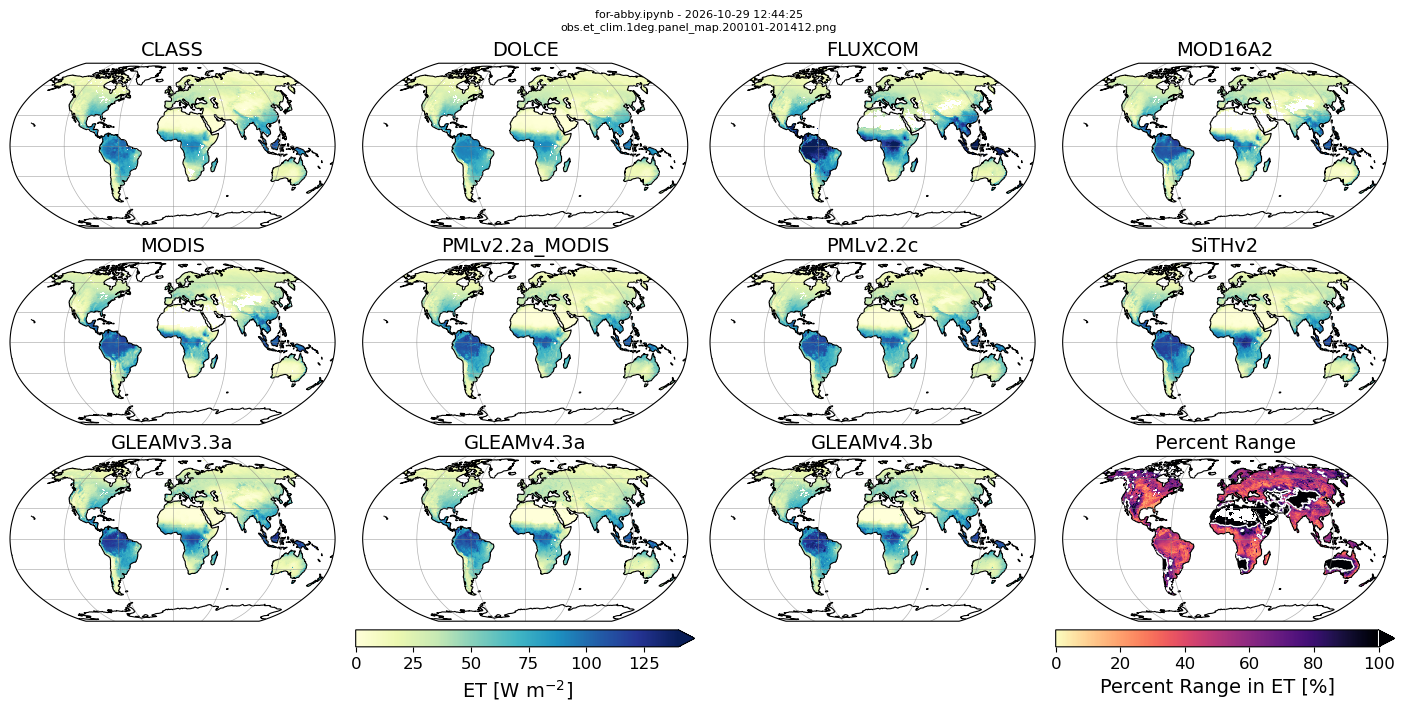

In [44]:
fam = "obs"

fig, axes = plt.subplots(3, 4, figsize=(14, 7), subplot_kw=dict(projection=ccrs.Robinson()), layout="constrained")
axs = axes.ravel()

for ax, m, etp in zip(axs, ORD_MEMBER, inputs[fam]["et_clim"].sel(member=ORD_MEMBER).et_product):
    mappable = inputs[fam]["et_clim"].et.sel(member=m).mean(dim="year").plot(
        ax=ax, 
        cmap=MAP_KWARGS["et"]["cmap"],
        vmin=0, vmax=140,
        add_labels=False,
        add_colorbar=False,
        transform=ccrs.PlateCarree(),
    )
    ax.set_global()
    ax.gridlines(color="gray", linewidth=0.5, alpha=0.6)
    ax.coastlines(lw=0.8, color="k")
    ax.set_title(etp.item(), fontsize=14)

cb = fig.colorbar(
    mappable,
    extend="max",
    # ax=axs[:-1],
    # fraction=0.025,
    # pad=0.01,
    ax=axs[-3],
    location="bottom",
)
cb.set_label("ET [W m$^{-2}$]", fontsize=14)
cb.ax.tick_params(labelsize=12)

# axs[-1].remove()

mappable = rng_rel[fam].plot(
    ax=axs[-1],
    vmin=RNG_VMIN,
    vmax=100,
    cmap=RNG_CMAP,
    add_labels=False,
    add_colorbar=False,
    transform=ccrs.PlateCarree(),
)
rng_rel[fam].plot.contour(
    ax=axs[-1], levels=[RNG_CONTOUR], colors="white", linewidths=1,
    transform=ccrs.PlateCarree(),
)
axs[-1].set_global()
axs[-1].gridlines(color="gray", linewidth=0.5, alpha=0.6)
axs[-1].coastlines(lw=0.8, color="k")
axs[-1].set_title("Percent Range", fontsize=14)
cb = fig.colorbar(
    mappable,
    extend="max",
    # ax=axs[:-1],
    # fraction=0.025,
    # pad=0.01,
    ax=axs[-1],
    location="bottom",
)
cb.set_label("Percent Range in ET [%]", fontsize=14)
cb.ax.tick_params(labelsize=12)
cb.ax.axvline(RNG_CONTOUR, c="white", lw=1.5)

fout = cfg.output_dir(FIG_ROOT, "obs", "clim", PERIOD) / f"obs.{ET_BIN_VARIABLE}.1deg.panel_map.{PERIOD}.png"
finish(fig, fout, to_save=TO_SAVE)

## Range over map

In [7]:
def map_range(fam, vmin=RNG_VMIN, vmax=RNG_VMAX, cmap=RNG_CMAP, contour=[RNG_CONTOUR], tag="", to_save=False):
    fig, ax = plt.subplots(figsize=(8, 4), subplot_kw=dict(projection=ccrs.Robinson()), layout="constrained")
    mappable = rng_rel[fam].plot(
        ax=ax,
        vmin=vmin,
        vmax=(vmax + 1 if vmax == contour[-1] else vmax),
        cmap=cmap,
        add_labels=False,
        add_colorbar=False,
        transform=ccrs.PlateCarree(),
    )
    ax.set_global()
    ax.gridlines(color="gray", linewidth=0.5, alpha=0.6)
    ax.coastlines(lw=0.8, color="k")
    cb = fig.colorbar(
        mappable,
        extend="max",
        fraction=0.1,
        ax=ax,
        location="bottom",
    )
    cb.set_label("Percent Range in ET [%]", fontsize=14)
    cb.ax.tick_params(labelsize=12)

    if contour is not None:
        if len(contour) == 2:
            lws = [0.5, 1]
            rng_rel[fam].plot.contour(
                ax=ax, levels=contour,
                colors="white",
                linewidths=lws,
                linestyles="-",
                transform=ccrs.PlateCarree(),
                add_labels=False,
            )
            for c, w in zip(contour, lws):
                cb.ax.axvline(c, c="white", lw=w, ls="-", zorder=100)
        elif len(contour) == 1:
            rng_rel[fam].plot.contour(
                ax=ax, levels=contour,
                colors="white",
                linewidths=1,
                linestyles="-",
                transform=ccrs.PlateCarree(),
                add_labels=False,
            )
            cb.ax.axvline(contour, c="white", lw=1.5, ls="-", zorder=100)
        else:
            print("Warning: Only {0, 1, 2} contours allowed")

    if len(tag) > 0:
        tag += "."
    else:
        tag = f"vmax{vmax}."
    fout = cfg.output_dir(FIG_ROOT, fam, "clim", PERIOD) / f"{fam}.{ET_BIN_VARIABLE}.1deg.rng_rel_map.{PERIOD}.{tag}png"
    finish(fig, fout, to_save=to_save)

saved: /glade/u/home/bbuchovecky/projects/et_unc/for/aswann/obs/clim/200101-201412/obs.et_clim.1deg.rng_rel_map.200101-201412.vmax100.png


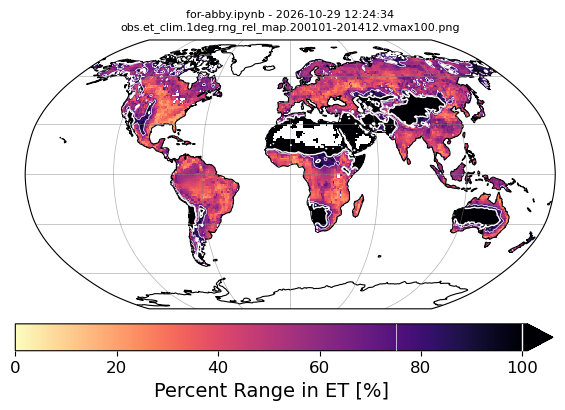

In [8]:
map_range("obs", contour=[75, 100], vmax=100, to_save=TO_SAVE)

saved: /glade/u/home/bbuchovecky/projects/et_unc/for/aswann/obs/clim/200101-201412/obs.et_clim.1deg.rng_rel_map.200101-201412.vmax200.png


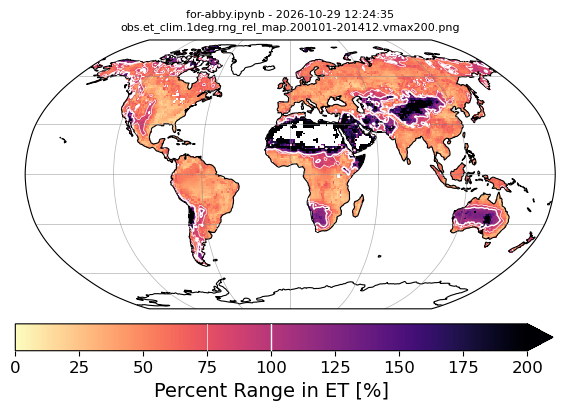

In [9]:
map_range("obs", contour=[75, 100], vmax=200, to_save=TO_SAVE)

saved: /glade/u/home/bbuchovecky/projects/et_unc/for/aswann/cmip/clim/200101-201412/cmip.et_clim.1deg.rng_rel_map.200101-201412.vmax200.png


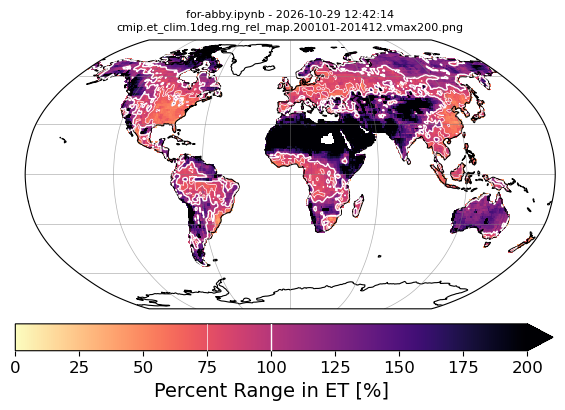

In [42]:
map_range("cmip", contour=[75, 100], vmax=200, to_save=TO_SAVE)

saved: /glade/u/home/bbuchovecky/projects/et_unc/for/aswann/fppe/clim/200101-201412/fppe.et_clim.1deg.rng_rel_map.200101-201412.vmax100.png


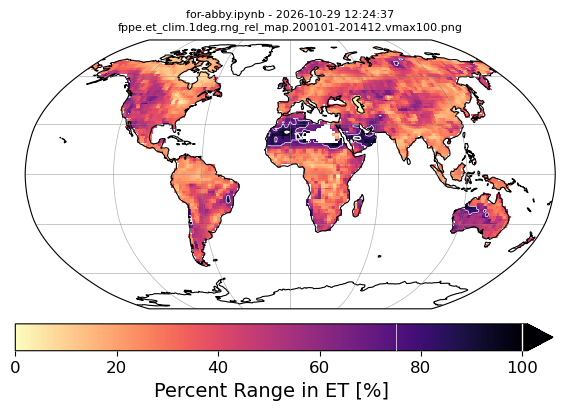

In [11]:
map_range("fppe", contour=[75, 100], vmax=100, to_save=TO_SAVE)

saved: /glade/u/home/bbuchovecky/projects/et_unc/for/aswann/fppe/clim/200101-201412/fppe.et_clim.1deg.rng_rel_map.200101-201412.vmax200.png


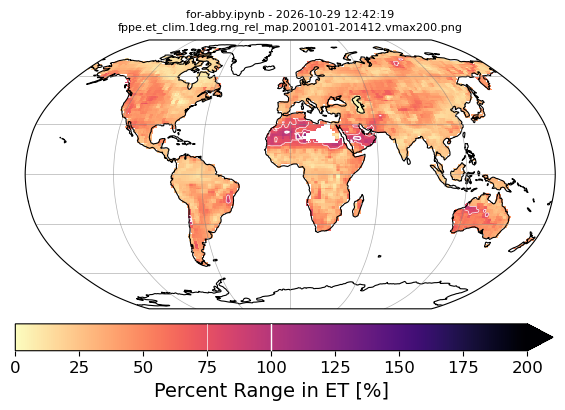

In [43]:
map_range("fppe", contour=[75, 100], vmax=200, to_save=TO_SAVE)

## Range over bins

In [32]:
def bin_range(fam, vmin=RNG_VMIN, vmax=RNG_VMAX, cmap=RNG_CMAP, contour=RNG_CONTOUR, tag="", to_save=False):
    fig, ax = plt.subplots(figsize=(6, 5), layout="constrained")
    mappable = qbin_rng_rel[fam].plot(
        ax=ax,
        cmap=cmap,
        vmin=vmin,
        vmax=vmax,
        add_labels=False,
        add_colorbar=False,
    )
    set_edge_ticks(ax, qbin_rng_rel[fam], "{:.1f}")
    ax.tick_params(axis='both', labelsize=10)
    ax.set_xlabel("Aridity, $R_n \\: / \\: L_v P$", fontsize=14)
    ax.set_ylabel("LAI [m$^2$/m$^2$]", fontsize=14)
    cb = fig.colorbar(
        mappable,
        ax=ax,
        extend="max",
    )
    cb.set_label("Percent Range in ET [%]", fontsize=14)
    cb.ax.tick_params(labelsize=12)

    if len(tag) > 0:
        tag += "."
    else:
        tag = f"vmax{vmax}."
    fout = cfg.output_dir(FIG_ROOT, fam, "qbin", PERIOD, BINS) / f"{fam}.{ET_BIN_VARIABLE}.{TAG}.rng_rel.{tag}png"
    finish(fig, fout, to_save=to_save)

saved: /glade/u/home/bbuchovecky/projects/et_unc/for/aswann/obs/qbin/200101-201412/lai15_ai15/obs.et_clim.qbin_pooled_all.lai15_ai15.1deg.200101-201412.rng_rel.vmax100.png


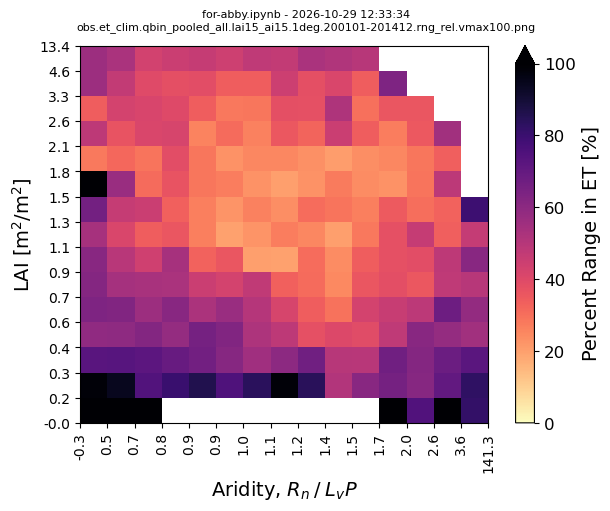

In [33]:
bin_range("obs", vmax=100, to_save=TO_SAVE)

saved: /glade/u/home/bbuchovecky/projects/et_unc/for/aswann/obs/qbin/200101-201412/lai15_ai15/obs.et_clim.qbin_pooled_all.lai15_ai15.1deg.200101-201412.rng_rel.vmax200.png


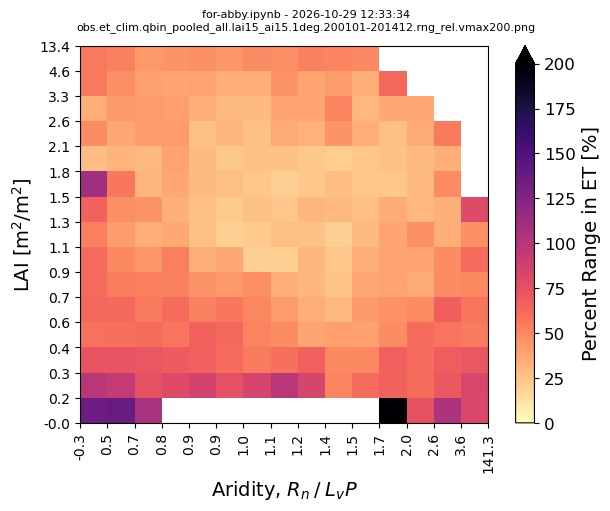

In [34]:
bin_range("obs", vmax=200, to_save=TO_SAVE)

saved: /glade/u/home/bbuchovecky/projects/et_unc/for/aswann/cmip/qbin/200101-201412/lai15_ai15/cmip.et_clim.qbin_pooled_all.lai15_ai15.1deg.200101-201412.rng_rel.vmax100.png


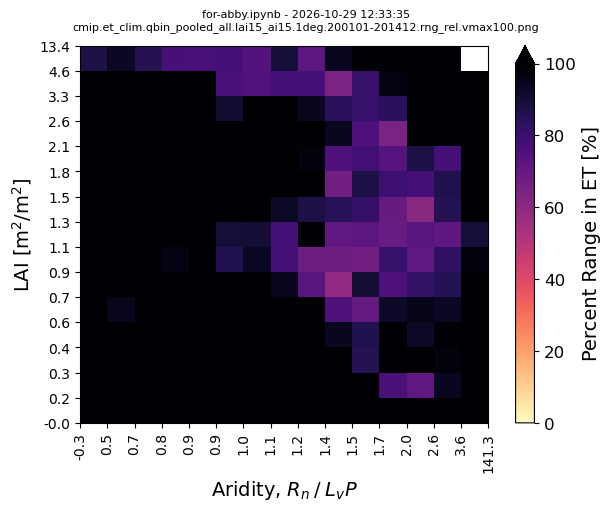

In [35]:
bin_range("cmip", vmax=100, to_save=TO_SAVE)

saved: /glade/u/home/bbuchovecky/projects/et_unc/for/aswann/cmip/qbin/200101-201412/lai15_ai15/cmip.et_clim.qbin_pooled_all.lai15_ai15.1deg.200101-201412.rng_rel.vmax200.png


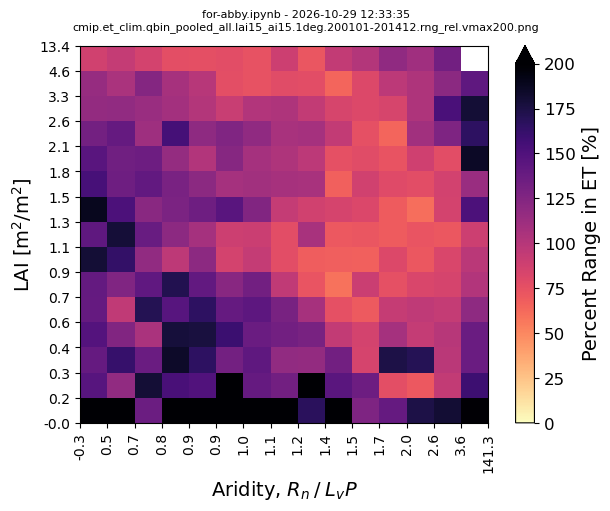

In [36]:
bin_range("cmip", vmax=200, to_save=TO_SAVE)

saved: /glade/u/home/bbuchovecky/projects/et_unc/for/aswann/fppe/qbin/200101-201412/lai15_ai15/fppe.et_clim.qbin_pooled_all.lai15_ai15.1deg.200101-201412.rng_rel.vmax100.png


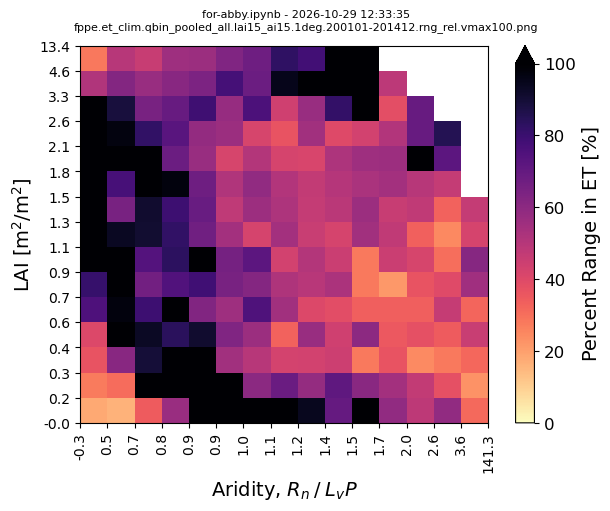

In [37]:
bin_range("fppe", vmax=100, to_save=TO_SAVE)

saved: /glade/u/home/bbuchovecky/projects/et_unc/for/aswann/fppe/qbin/200101-201412/lai15_ai15/fppe.et_clim.qbin_pooled_all.lai15_ai15.1deg.200101-201412.rng_rel.vmax200.png


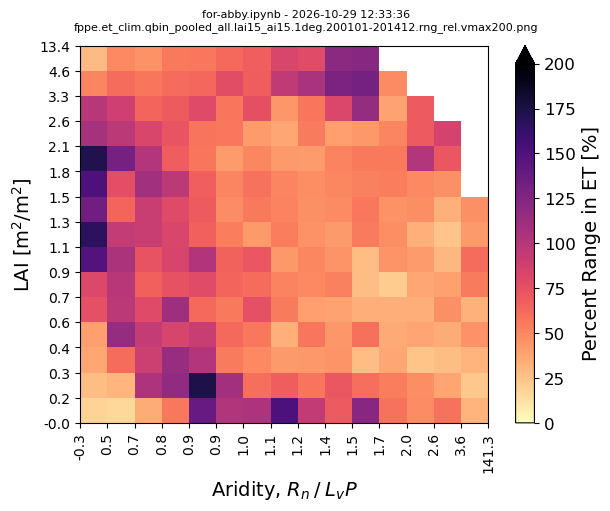

In [38]:
bin_range("fppe", vmax=200, to_save=TO_SAVE)

## Compare bin range between data families

In [20]:
obs_avg = qbin["obs"]["et_clim"].et.sel(stats="mean").mean(dim="member")
obs_max = qbin["obs"]["et_clim"].et.sel(stats="mean").max(dim="member")
obs_min = qbin["obs"]["et_clim"].et.sel(stats="mean").min(dim="member")

In [21]:
cmip_et = qbin["cmip"]["et_clim"].et.sel(stats="mean")
fppe_et = qbin["fppe"]["et_clim"].et.sel(stats="mean")

In [22]:
def outside_obs_range(et):
    return (et > obs_max) | (et < obs_min)

cmip_obs_rng_et = outside_obs_range(cmip_et)
fppe_obs_rng_et = outside_obs_range(fppe_et)

saved: /glade/u/home/bbuchovecky/projects/et_unc/for/aswann/fppe/qbin/200101-201412/lai15_ai15/fppe.et_clim.qbin_pooled_all.lai15_ai15.1deg.200101-201412.out_obs_rng.png


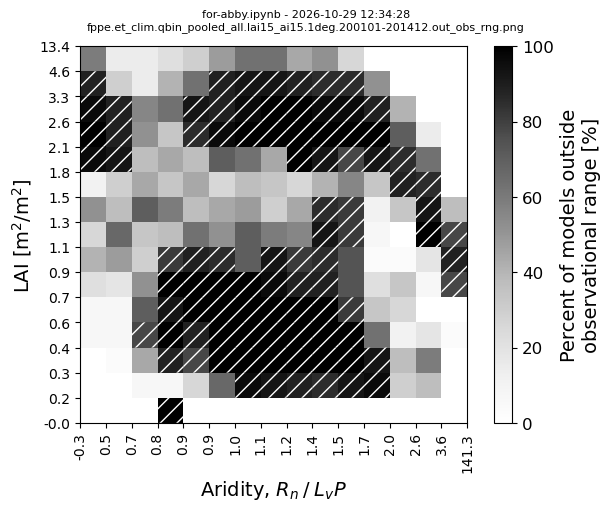

In [40]:
fam = "fppe"
da = fppe_obs_rng_et.sum(dim="member") / len(fppe_et.member) * 100

fig, ax = plt.subplots(figsize=(6, 5), layout="constrained")
mappable = da.plot(
    ax=ax,
    cmap="Greys",
    vmin=0,
    vmax=100,
    add_labels=False,
    add_colorbar=False,
)
set_edge_ticks(ax, qbin_rng_rel[fam], "{:.1f}")
ax.pcolor(
    da.x_bin,
    da.y_bin,
    da.where(da > 75),
    facecolor="none", edgecolor="white", hatch="//", linewidth=0,
)
ax.tick_params(axis='both', labelsize=10)
ax.set_xlabel("Aridity, $R_n \\: / \\: L_v P$", fontsize=14)
ax.set_ylabel("LAI [m$^2$/m$^2$]", fontsize=14)
cb = fig.colorbar(
    mappable,
    ax=ax,
)
cb.set_label("Percent of models outside\nobservational range [%]", fontsize=14)
cb.ax.tick_params(labelsize=12)

fout = cfg.output_dir(FIG_ROOT, fam, "qbin", PERIOD, BINS) / f"{fam}.{ET_BIN_VARIABLE}.{TAG}.out_obs_rng.png"
finish(fig, fout, to_save=TO_SAVE)

saved: /glade/u/home/bbuchovecky/projects/et_unc/for/aswann/cmip/qbin/200101-201412/lai15_ai15/cmip.et_clim.qbin_pooled_all.lai15_ai15.1deg.200101-201412.out_obs_rng.png


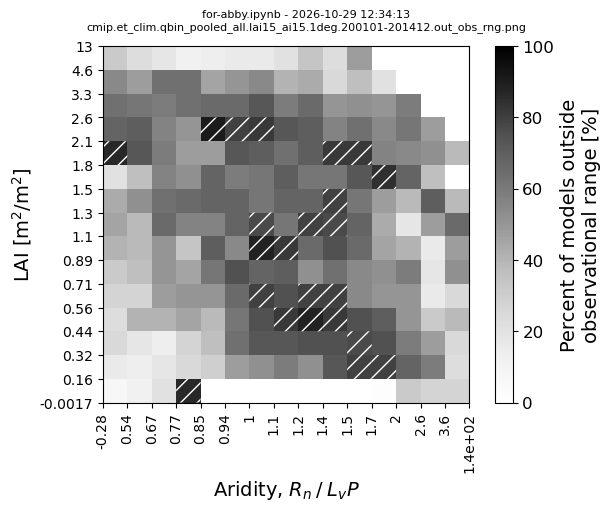

In [39]:
fam = "cmip"
da = cmip_obs_rng_et.sum(dim="member") / len(cmip_et.member) * 100

fig, ax = plt.subplots(figsize=(6, 5), layout="constrained")
mappable = da.plot(
    ax=ax,
    cmap="Greys",
    vmin=0,
    vmax=100,
    add_labels=False,
    add_colorbar=False,
)
set_edge_ticks(ax, qbin_rng_rel[fam], "{:.2g}")
ax.pcolor(
    da.x_bin,
    da.y_bin,
    da.where(da > 75),
    facecolor="none", edgecolor="white", hatch="//", linewidth=0,
)
ax.tick_params(axis='both', labelsize=10)
ax.set_xlabel("Aridity, $R_n \\: / \\: L_v P$", fontsize=14)
ax.set_ylabel("LAI [m$^2$/m$^2$]", fontsize=14)
cb = fig.colorbar(
    mappable,
    ax=ax,
)
cb.set_label("Percent of models outside\nobservational range [%]", fontsize=14)
cb.ax.tick_params(labelsize=12)

fout = cfg.output_dir(FIG_ROOT, fam, "qbin", PERIOD, BINS) / f"{fam}.{ET_BIN_VARIABLE}.{TAG}.out_obs_rng.png"
finish(fig, fout, to_save=TO_SAVE)

In [25]:
cmip_tla = qbin["cmip"]["land_area"].land_area.isel(member=0).sum(dim=["x_bin", "y_bin"])
fppe_tla = qbin["fppe"]["land_area"].land_area.isel(member=0).sum(dim=["x_bin", "y_bin"])
print((cmip_tla - fppe_tla).item())

cmip_pla_obs_rng_et = qbin["cmip"]["land_area"].land_area.where(cmip_obs_rng_et).sum(dim=["x_bin", "y_bin"]) / cmip_tla * 100
fppe_pla_obs_rng_et = qbin["fppe"]["land_area"].land_area.where(fppe_obs_rng_et).sum(dim=["x_bin", "y_bin"]) / fppe_tla * 100

0.0


saved: /glade/u/home/bbuchovecky/projects/et_unc/for/aswann/all/qbin/200101-201412/lai15_ai15/all.et_clim.qbin_pooled_all.lai15_ai15.1deg.200101-201412.out_obs_rng_fla.png


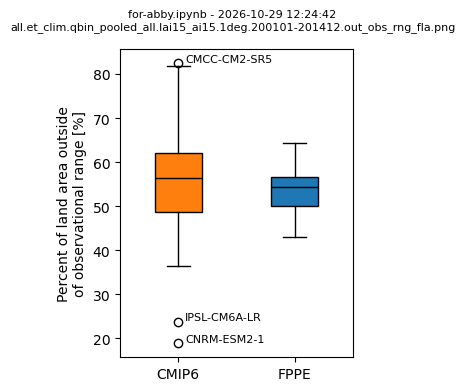

In [26]:
colors = ["tab:orange", "tab:blue"]
labels = ["CMIP6", "FPPE"]
medianprops = dict(linewidth=1, color="k")

fig, ax = plt.subplots(figsize=(3, 4))

bp = ax.boxplot(
    [cmip_pla_obs_rng_et, fppe_pla_obs_rng_et],
    widths=0.4,
    meanline=False,
    medianprops=medianprops,
    patch_artist=True,
    tick_labels=labels,
)

for p, c in zip(bp['boxes'], colors):
    p.set_facecolor(c)

for i, line in enumerate(bp['fliers']):
    xdata = np.array(line.get_xdata())
    ydata = np.array(line.get_ydata())

    xdata = xdata[np.argsort(ydata)]
    ydata = np.sort(ydata)

    for x, y in zip(xdata, ydata):
        idx = np.where(np.isin(cmip_pla_obs_rng_et, y))
        m = cmip_pla_obs_rng_et.member[idx].item().split(".")[0]
        ax.annotate(
            # f'{y:.1f}',
            m,
            (x, y),
            textcoords='offset points',
            xytext=(5, 3),
            ha='left',
            va="center",
            fontsize=8,
        )

ax.set_ylabel("Percent of land area outside\nof observational range [%]")

fout = cfg.output_dir(FIG_ROOT, "all", "qbin", PERIOD, BINS) / f"all.{ET_BIN_VARIABLE}.{TAG}.out_obs_rng_fla.png"
finish(fig, fout, to_save=TO_SAVE)

## Bin land area

In [27]:
# qbin["obs"]["land_area"].land_area_frac.plot(col="member", col_wrap=4, robust=True, cmap="PuRd")

In [28]:
# qbin_lf = qbin["land_area"].land_area_frac * 100
# qbin_lf_rng = qbin_lf.max(dim="member") - qbin_lf.min(dim="member")
# qbin_lf_avg = qbin_lf.mean(dim="member")

# # .plot(col="member", col_wrap=4, robust=True, cmap="PuRd")

In [29]:
# qbin_lf_avg.plot(cmap="PuRd", robust=True)

In [30]:
# qbin_lf_rng.plot(cmap="PuRd", robust=True)